In [7]:
import os
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns


In [8]:
# ==============================================================================
# CONFIGURAÇÕES E FLAGS DE FILTRO
# ==============================================================================
CSV_PATH = "wu_shen_selected_columns.csv"  # Substitua pelo caminho do seu catálogo

# Nomes exatos das colunas no seu arquivo
COL_Z = "Z_DR16Q"  # Redshift
COL_MASS = "LOGMBH"  # Massa do BH
COL_EDD = "LOGLEDD_RATIO"  # Razão de Eddington
COL_SNR = "SN_MEDIAN_ALL"  # Coluna de Sinal-Ruído (ex: 'SN_MEDIAN_ALL', 'SNR', etc.)

# --- FLAG 1: FILTRO DE SINAL-RUÍDO (Ativo por padrão com S/N >= 20) ---
APPLY_SNR_FILTER = True
MIN_SNR = 20.0

# --- FLAG 2: FILTRO DE REDSHIFT ---
APPLY_Z_FILTER = False  # Altere para False se não quiser cortar faixa de z
Z_MIN = 0.40
Z_MAX = 0.50

# --- FLAGS ADICIONAIS OPCIONAIS (Massa e Eddington) ---
APPLY_MASS_FILTER = False
MASS_MIN = 7.0
MASS_MAX = 10.5

APPLY_EDD_FILTER = False
EDD_MIN = -2.5
EDD_MAX = 0.2

Carregando catálogo...
-> Filtro S/N >= 20.0 aplicado.
Total de objetos selecionados: 16162 (de 750414 iniciais)


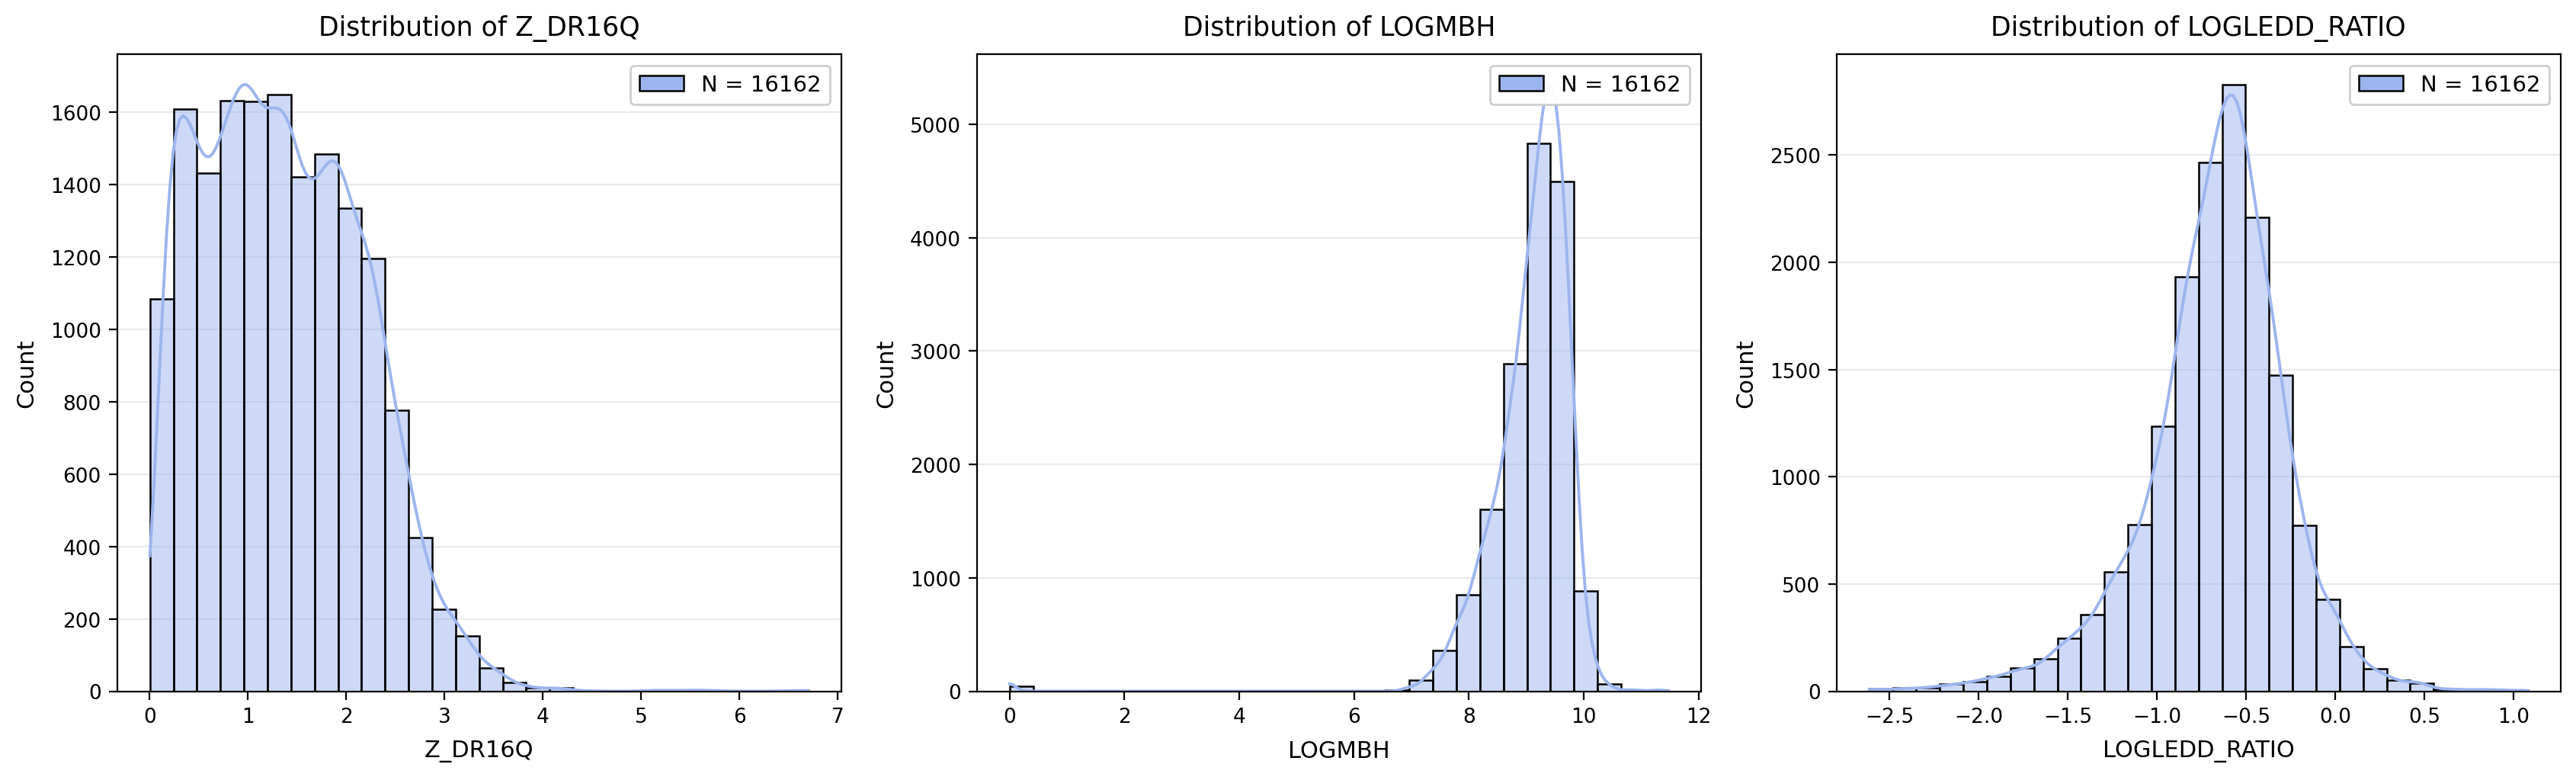

In [9]:

# ==============================================================================
# 1. CARREGAMENTO E APLICAÇÃO DOS FILTROS
# ==============================================================================
print("Carregando catálogo...")
df = pd.read_csv(CSV_PATH)
n_inicial = len(df)

# Remover NaNs nas colunas essenciais
df = df.dropna(subset=[COL_Z, COL_MASS, COL_EDD]).copy()

# Aplicação dos filtros condicionais
if APPLY_SNR_FILTER:
    if COL_SNR in df.columns:
        df = df[df[COL_SNR] >= MIN_SNR]
        print(f"-> Filtro S/N >= {MIN_SNR} aplicado.")
    else:
        print(
            f"Aviso: Coluna '{COL_SNR}' não encontrada. Filtro de S/N ignorado."
        )

if APPLY_Z_FILTER:
    df = df[(df[COL_Z] >= Z_MIN) & (df[COL_Z] <= Z_MAX)]
    print(f"-> Filtro Redshift [{Z_MIN}, {Z_MAX}] aplicado.")

if APPLY_MASS_FILTER:
    df = df[(df[COL_MASS] >= MASS_MIN) & (df[COL_MASS] <= MASS_MAX)]

if APPLY_EDD_FILTER:
    df = df[(df[COL_EDD] >= EDD_MIN) & (df[COL_EDD] <= EDD_MAX)]

n_final = len(df)
print(f"Total de objetos selecionados: {n_final} (de {n_inicial} iniciais)")

if n_final == 0:
    raise ValueError(
        "Nenhum objeto restante após os cortes. Verifique os limites dos filtros."
    )

# ==============================================================================
# 2. CONFIGURAÇÃO VISUAL E PLOT DOS 3 HISTOGRAMAS
# ==============================================================================
# Paleta idêntica ao exemplo: barras em azul suave, linha em azul royal
BAR_COLOR = "#9cb5ee"
LINE_COLOR = "#2355ba"

cols_to_plot = [
    (COL_Z, f"Distribution of {COL_Z}", 28),
    (COL_MASS, f"Distribution of {COL_MASS}", 28),
    (COL_EDD, f"Distribution of {COL_EDD}", 28),
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), dpi=200)

for ax, (col_name, title, n_bins) in zip(axes, cols_to_plot):
    # Plot do histograma com KDE
    sns.histplot(
        data=df,
        x=col_name,
        bins=n_bins,
        kde=True,
        color=BAR_COLOR,
        edgecolor="black",
        linewidth=0.9,
        line_kws={"color": LINE_COLOR, "linewidth": 1.4},
        ax=ax,
    )

    # Configurações de eixos e títulos
    ax.set_title(title, fontsize=12.5, pad=9, fontweight="normal")
    ax.set_xlabel(col_name, fontsize=11, labelpad=6)
    ax.set_ylabel("Count", fontsize=11, labelpad=6)

    # Grid sutil apenas no eixo horizontal (eixo Y), exatamente como na foto
    ax.grid(axis="y", color="#eaeaea", linestyle="-", linewidth=0.8)
    ax.set_axisbelow(True)

    # Ticks nítidos voltados para fora
    ax.tick_params(direction="out", length=4, width=0.8, labelsize=9.5)

    # Legenda idêntica (caixa com contorno preto e texto N = ...)
    legend_patch = mpatches.Patch(
        facecolor=BAR_COLOR,
        edgecolor="black",
        linewidth=0.9,
        label=f"N = {n_final}",
    )
    ax.legend(
        handles=[legend_patch],
        loc="upper right",
        frameon=True,
        framealpha=0.95,
        edgecolor="#cccccc",
        fontsize=10.5,
    )

plt.tight_layout()
plt.savefig("distribuicoes_qso.png", dpi=300, bbox_inches="tight")
plt.show()